# Nitrate Risk Map — Random Forest (Probability of Exceeding 10 mg/L)

**Objective:** Predict the probability that groundwater nitrate exceeds 10 mg/L for every grid cell in the Salinas Valley, including areas without sampled wells.

**How it differs from the preview map in the slides:** the preview only averaged predictions *at sampled wells* into nearby cells. Here, every cell is treated as a new, hypothetical domestic well: its own soil, terrain, climate, land-use and subbasin features are computed with the **same methods used for the wells** (`all_merge_final.ipynb` and `crop_mapping_annual_2021_2024.ipynb`), and the final random forest predicts each cell.

**Steps**
1. Train the final model once: the tuned random forest from `classification_models.ipynb` (same grid and search), on all training wells (folds 0–3).
2. Build a grid over the Salinas Valley groundwater basin, keeping cells within a set distance of training wells (the model's domain).
3. Compute the 59 model features for each cell.
4. Predict, group into risk levels.
5. **Hybrid version:** correct the model with the measurements at nearby wells (residuals within 2 km).
6. Map both versions and save.

**Inputs (local only, not in Git):** `data/soils/soils_huc8_attributes.gpkg`, `data/elevation/dem_watershed_10m.tif`, and the DWR statewide crop map geodatabases (folder set by `ERDOS_CROPS_DIR`, default `Data/Erdos Project/raw/Crops`, as in the crop notebook).

**Outputs:** `results/risk_map/risk_map_<cell size>m.csv` plus one `.png` per version (in Git); a GeoPackage with cell polygons and one GeoTIFF per version in `data/outputs/` (local, for ArcGIS).

**Runtime:** the crop overlay is the slow step. Start with `TEST_CELLS = 300` to check everything runs, then set it to `None` for the full map. A 500 m grid has roughly 4 times fewer cells than 250 m.

In [1]:
import os
import sys
import time
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import rasterio
import shapely
from rasterio.mask import mask
from shapely.geometry import box, mapping
from pyproj import Transformer
from scipy.spatial import cKDTree
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

from src.features.preprocessing import load_model_data, load_selected_features
from src.features.transformers import build_features, add_subbasin, subbasin_dummies, SUBBASIN_PATH
from src.evaluation.make_splits import load_split
from src.models.evaluate import tuned, predictions_path

## 0. Settings

In [2]:
# ===== Map settings =====
CELL_SIZE_M = 500                # grid cell size; 250 for the final map (about 4x slower)
MAX_DISTANCE_TO_WELL_M = 3000    # cells farther than this from any training well are outside the model's domain
TEST_CELLS = None                # e.g. 300 for a quick test run; None for the full map

# ===== Reference conditions for a hypothetical domestic well =====
CROP_YEAR = 2024                              # crop map used (lag-1 for a 2025 sample); CROP_YEAR - 1 is used for annual change
REFERENCE_DATE = pd.Timestamp("2025-07-01")   # sample date used for the PRISM climate features
WELL_CATEGORY = "Domestic"

# ===== Final model: the tuned random forest from classification_models.ipynb =====
SPLIT = "10km_subbasin"
FIT_ON = "all"                   # "all" = every well (the hold-out evaluation is done); "train_val" = folds 0-3 only
RF_GRID = {                      # same grid and search as classification_models.ipynb
    "max_depth": [6, 8, 11, 15, None],
    "max_features": ["sqrt", 0.3, 0.5],
    "min_samples_leaf": [1, 5, 20],
}

DECISION_THRESHOLD = 0.4         # team's threshold for calling an exceedance (final_results.ipynb)

# ===== Paths =====
METRIC_CRS = 3310
SOIL_PATH = ROOT / "data" / "soils" / "soils_huc8_attributes.gpkg"
DEM_PATH = ROOT / "data" / "elevation" / "dem_watershed_10m.tif"
PRISM_PATH = ROOT / "notebooks" / "data_cleaning" / "precipitation" / "prism_climate_monthly_clean.csv"
CROPS_DIR = Path(os.environ.get("ERDOS_CROPS_DIR",
                                ROOT.parent.parent / "Data" / "Erdos Project" / "raw" / "Crops"))
RESULTS_DIR = ROOT / "results" / "risk_map"
LOCAL_OUTPUT_DIR = ROOT / "data" / "outputs"

missing = [p for p in [SOIL_PATH, DEM_PATH, PRISM_PATH, CROPS_DIR, SUBBASIN_PATH] if not Path(p).exists()]
if missing:
    raise FileNotFoundError("Missing inputs:\n" + "\n".join(map(str, missing)))
print("DWR crop maps:", CROPS_DIR)

DWR crop maps: C:\Users\lomel\Documents\Data Science\Data\Erdos Project\raw\Crops


## 1. Final model

Cross-validation trained four temporary models (one per fold) only to *measure* performance; they were not kept. The map needs one model, so the random forest is tuned and trained once on all training wells, with the same grid and search as in `classification_models.ipynb` (300 trees, settings chosen by Brier score with one spatial fold held out at a time).

The hold-out evaluation in `final_results.ipynb` is done, so the map model is trained on **all** wells (`FIT_ON = "all"`), the usual practice once a model has been evaluated: it adds the hold-out wells, including about half of the East Side Aquifer samples.

In [3]:
X, y, meta = load_model_data(subbasin=True)
FEATURES = list(X.columns)
data = load_split(pd.concat([meta, X], axis=1).assign(log_nitrate=y), split=SPLIT)

train = data[~data["holdout"]] if FIT_ON == "train_val" else data
exceeds = np.expm1(train["log_nitrate"]) > 10

search = tuned(RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=1),
               RF_GRID, "neg_brier_score", n_iter=10)
search.fit(train[FEATURES], exceeds, groups=train["fold"])
model = search.best_estimator_
print("Selected settings:", search.best_params_)
print(f"Trained on {len(train):,} samples from {train['gm_well_id'].nunique():,} wells ({FIT_ON}); "
      f"{len(FEATURES)} features; {exceeds.mean():.0%} exceed 10 mg/L")

Selected settings: {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': None}
Trained on 5,280 samples from 1,993 wells (all); 59 features; 34% exceed 10 mg/L


## 2. Grid and model domain

Cell centers inside the Salinas Valley groundwater basin (DWR Bulletin 118 subbasins). Only cells within `MAX_DISTANCE_TO_WELL_M` of a training well are predicted, so the model is not applied to conditions far from where it learned.

In [4]:
subbasins = gpd.read_file(SUBBASIN_PATH).to_crs(METRIC_CRS)
basin = subbasins.union_all()

wells = train.drop_duplicates("gm_well_id")
wells = gpd.GeoDataFrame(wells[["gm_well_id"]],
                         geometry=gpd.points_from_xy(wells.gm_longitude, wells.gm_latitude),
                         crs=4326).to_crs(METRIC_CRS)
well_xy = np.c_[wells.geometry.x, wells.geometry.y]

xmin, ymin, xmax, ymax = basin.bounds
xs = np.arange(xmin + CELL_SIZE_M / 2, xmax, CELL_SIZE_M)
ys = np.arange(ymin + CELL_SIZE_M / 2, ymax, CELL_SIZE_M)
gx, gy = np.meshgrid(xs, ys)
centers = gpd.GeoDataFrame(geometry=gpd.points_from_xy(gx.ravel(), gy.ravel()), crs=METRIC_CRS)
centers = centers[centers.within(basin)].reset_index(drop=True)

distance, _ = cKDTree(well_xy).query(np.c_[centers.geometry.x, centers.geometry.y])
cells = centers[distance <= MAX_DISTANCE_TO_WELL_M].reset_index(drop=True)

if TEST_CELLS:
    # A compact test area: the cells closest to the median training well
    center = np.median(well_xy, axis=0)
    order = np.argsort(np.hypot(cells.geometry.x - center[0], cells.geometry.y - center[1]))
    cells = cells.iloc[np.sort(order[:TEST_CELLS])].reset_index(drop=True)

cells["gm_well_id"] = [f"C{i:06d}" for i in range(len(cells))]
lonlat = cells.to_crs(4326).geometry
cells["gm_latitude"], cells["gm_longitude"] = lonlat.y.to_numpy(), lonlat.x.to_numpy()
cells["x"], cells["y"] = cells.geometry.x, cells.geometry.y

print(f"{len(centers):,} cells in the basin | {int((distance <= MAX_DISTANCE_TO_WELL_M).sum()):,} within "
      f"{MAX_DISTANCE_TO_WELL_M / 1000:g} km of a training well | {len(cells):,} cells to predict"
      + (" (test run)" if TEST_CELLS else ""))

16,154 cells in the basin | 7,787 within 3 km of a training well | 7,787 cells to predict


## 3. Features for each cell

Each block reproduces the method used for the wells.

### 3.1 Soils (SSURGO, area-weighted within 500 m)

In [5]:
def soil_features(points, soils, radius=500, batch_size=500):
    """Area-weighted SSURGO attributes within a circle around each point (as in all_merge_final)."""
    numeric_fields = ["slopegradwta", "brockdepmin", "aws0150wta"]
    category_fields = ["drclassdcd", "hydgrpdcd"]
    category_values = {name: sorted(soils[name].dropna().unique(), key=str) for name in category_fields}
    columns = numeric_fields + category_fields
    out = []
    for start in range(0, len(points), batch_size):
        batch = points.iloc[start:start + batch_size][["gm_well_id", "geometry"]].copy()
        batch.geometry = batch.buffer(radius)
        candidates = gpd.sjoin(batch, soils[columns + ["geometry"]], how="inner", predicate="intersects")
        if candidates.empty:
            pairs = candidates.assign(_area=pd.Series(dtype="float64"))
        else:
            pieces = shapely.intersection(candidates.geometry.array,
                                          soils.geometry.array.take(candidates["index_right"].to_numpy(dtype=int)))
            area = shapely.area(pieces)
            keep = np.isfinite(area) & (area > 0)
            pairs = candidates.loc[keep].assign(_area=area[keep])

        table = pd.DataFrame({"gm_well_id": batch["gm_well_id"].to_numpy()})
        buffer_area = batch.geometry.area.to_numpy()
        mapped = table.gm_well_id.map(pairs.groupby("gm_well_id")["_area"].sum()).fillna(0.0)
        table["soil_mapped_coverage_pct"] = 100 * mapped.to_numpy() / buffer_area
        for name in numeric_fields:
            valid = pairs[pairs[name].notna()]
            valid_area = valid.groupby("gm_well_id")["_area"].sum()
            weighted = (valid[name] * valid["_area"]).groupby(valid["gm_well_id"]).sum()
            table[f"soil_{name}"] = table.gm_well_id.map(weighted / valid_area).to_numpy()
        for name in category_fields:
            valid = pairs.dropna(subset=[name])
            valid_area = table.gm_well_id.map(valid.groupby("gm_well_id")["_area"].sum())
            by_category = valid.groupby(["gm_well_id", name], observed=True)["_area"].sum()
            for category in category_values[name]:
                label = str(category).strip().lower().replace(" ", "_").replace("/", "_")
                try:
                    area_c = by_category.xs(category, level=name)
                except KeyError:
                    area_c = pd.Series(dtype="float64")
                pct = 100 * table.gm_well_id.map(area_c).fillna(0.0) / valid_area
                table[f"soil_{name}_pct_{label}"] = pct.where(valid_area > 0).to_numpy()
        out.append(table)
    return pd.concat(out, ignore_index=True)


t0 = time.time()
soils = gpd.read_file(SOIL_PATH).to_crs(METRIC_CRS).reset_index(drop=True)
for name in ["slopegradwta", "brockdepmin", "aws0150wta"]:
    soils[name] = pd.to_numeric(soils[name], errors="coerce")
cell_soils = soil_features(cells, soils)
print(f"Soils done in {time.time() - t0:.0f} s | mean mapped coverage {cell_soils.soil_mapped_coverage_pct.mean():.1f}%")

Soils done in 8 s | mean mapped coverage 93.0%


### 3.2 Terrain (10 m DEM)

Elevation at the cell center, and topographic position = elevation minus the mean elevation within 500 m.

In [6]:
t0 = time.time()
terrain = []
with rasterio.open(DEM_PATH) as dem:
    points_dem = cells.to_crs(dem.crs)
    circles_dem = gpd.GeoSeries(cells.buffer(500), crs=METRIC_CRS).to_crs(dem.crs)
    values = [np.ma.asarray(v[0]).filled(np.nan)
              for v in dem.sample([(p.x, p.y) for p in points_dem.geometry], masked=True)]
    for cell_id, value, circle in zip(cells.gm_well_id, values, circles_dem):
        pixels, _ = mask(dem, [mapping(circle)], crop=True, filled=False)
        valid = pixels[0].compressed()
        valid = valid[np.isfinite(valid)]
        value = float(value) if np.isfinite(value) else np.nan
        terrain.append({"gm_well_id": cell_id, "elevation_m": value,
                        "topographic_position": value - (valid.mean() if len(valid) else np.nan)})
cell_terrain = pd.DataFrame(terrain)
print(f"Terrain done in {time.time() - t0:.0f} s")

Terrain done in 8 s


### 3.3 Climate (PRISM, nearest grid point)

Same definitions as for the wells, computed for `REFERENCE_DATE`: complete months before that date, and complete calendar years before it for the historical means.

In [7]:
climate = pd.read_csv(PRISM_PATH, parse_dates=["date"])
climate["precip_mm"] = climate.precip_in * 25.4
climate["tmean_c"] = (climate.tmean_f - 32) * 5 / 9
grid = climate[["point_id", "longitude", "latitude"]].drop_duplicates()
grid = gpd.GeoDataFrame(grid, geometry=gpd.points_from_xy(grid.longitude, grid.latitude),
                        crs=4326).to_crs(METRIC_CRS)
nearest = gpd.sjoin_nearest(cells[["gm_well_id", "geometry"]], grid[["point_id", "geometry"]], how="left")
nearest = nearest.drop_duplicates("gm_well_id").set_index("gm_well_id").point_id


def climate_for_date(point_data, sample_date):
    """Climate features from complete months/years before sample_date (as in all_merge_final)."""
    result = {}
    sample_month = sample_date.to_period("M")
    prior = point_data.loc[point_data.date.dt.to_period("M") < sample_month].copy()
    prior["period"] = prior.date.dt.to_period("M")
    for window in [3, 12]:
        periods = pd.period_range(end=sample_month - 1, periods=window, freq="M")
        values = prior.set_index("period").reindex(periods)
        complete = values.date.notna().all()
        result[f"previous_{window}_complete_months_precip_mm"] = values.precip_mm.sum() if complete else np.nan
        result[f"previous_{window}_complete_months_temperature_c"] = values.tmean_c.mean() if complete else np.nan
    prior["year"] = prior.date.dt.year
    full_years = prior.groupby("year").date.nunique()
    history = prior[prior.year.isin(full_years[full_years == 12].index)]
    result["historical_mean_annual_precip_mm"] = history.groupby("year").precip_mm.sum().mean()
    result["historical_mean_temperature_c"] = history.tmean_c.mean()
    return result


by_point = {pid: climate_for_date(group.sort_values("date"), REFERENCE_DATE)
            for pid, group in climate[climate.point_id.isin(nearest.unique())].groupby("point_id")}
cell_climate = pd.DataFrame([{"gm_well_id": cid, **by_point[pid]} for cid, pid in nearest.items()])
print(f"Climate: {nearest.nunique()} PRISM points used")

Climate: 125 PRISM points used


### 3.4 Land use (DWR crop maps, 500 m and 1,000 m)

Crop shares, crop cycles, multicropping and the unmapped share for `CROP_YEAR`, plus the annual change from `CROP_YEAR - 1`. The functions are copied from `crop_mapping_annual_2021_2024.ipynb`; cells are processed in batches.

In [8]:
RADII = (500, 1000)
GROUPS = ["veg_berry", "vineyard", "orchard", "grain_field_pasture", "idle_fallow", "urban"]
FARMED = ["veg_berry", "vineyard", "orchard", "grain_field_pasture"]
CLASS_GROUP = {
    "T": "veg_berry", "V": "vineyard", "D": "orchard", "C": "orchard",
    "Y": "orchard", "YP": "orchard", "G": "grain_field_pasture",
    "F": "grain_field_pasture", "P": "grain_field_pasture",
    "R": "grain_field_pasture", "I": "idle_fallow", "X": "idle_fallow",
}
CYCLES = {"S": 1, "D": 2, "T": 3, "Q": 4}


def require(ok, message):
    if not ok:
        raise ValueError(message)


def find_gdb(root, token):
    matches = [p.parent for p in Path(root).rglob("a00000001.gdbtable")
               if token.lower() in p.parent.name.lower()]
    require(len(matches) == 1, f"Expected one GDB for {token}; found {matches}")
    return matches[0]


def read_crop_map(path, boundary):
    layer = pyogrio.list_layers(path)[0, 0]
    info = pyogrio.read_info(path, layer=layer)
    xmin, ymin, xmax, ymax = boundary.total_bounds
    to_source = Transformer.from_crs(METRIC_CRS, info["crs"], always_xy=True)
    bbox = to_source.transform_bounds(xmin - 1001, ymin - 1001, xmax + 1001, ymax + 1001, densify_pts=41)
    data = pyogrio.read_dataframe(path, layer=layer, bbox=bbox)
    data.geometry = data.geometry.force_2d().to_crs(METRIC_CRS).buffer(0)
    letters = data.SYMB_CLASS.astype("string").str.split("|").str[0].str.strip().str.upper()
    data["crop_group"] = letters.map(CLASS_GROUP)
    data.loc[letters.str.startswith("U", na=False), "crop_group"] = "urban"
    data["crop_cycles"] = data.MULTIUSE.astype("string").str.strip().map(CYCLES)
    return data.reset_index(drop=True)


def summarize(points, candidates, radius):
    """Crop features within a circle around each point (from the crop mapping notebook)."""
    circles = points[["gm_well_id", "geometry"]].copy()
    circles.geometry = circles.buffer(radius, quad_segs=16)
    grouped = candidates.dissolve(by=["crop_group", "crop_cycles"]).reset_index()
    pieces = gpd.overlay(circles, grouped[["crop_group", "crop_cycles", "geometry"]],
                         how="intersection", keep_geom_type=True)
    pieces["area_m2"] = pieces.area
    ids = pd.Index(points.gm_well_id.astype("string"), name="gm_well_id")
    areas = pieces.pivot_table(index="gm_well_id", columns="crop_group", values="area_m2", aggfunc="sum")
    areas = areas.reindex(index=ids, columns=GROUPS, fill_value=0).fillna(0)
    mapped = pieces.groupby("gm_well_id").geometry.apply(lambda s: s.union_all().area).reindex(ids, fill_value=0)
    circle_area = np.pi * radius**2
    buffer_area = pd.Series(circles.area.to_numpy(), index=ids)

    table = pd.DataFrame(index=ids)
    for group in GROUPS:
        table[f"pct_{group}_{radius}m"] = areas[group] / circle_area * 100
    table[f"pct_cropland_{radius}m"] = areas[FARMED].sum(axis=1) / circle_area * 100
    farm = pieces[pieces.crop_group.isin(FARMED)]
    farm_area = farm.groupby("gm_well_id").area_m2.sum().reindex(ids, fill_value=0)
    weighted = (farm.area_m2 * farm.crop_cycles).groupby(farm.gm_well_id).sum()
    table[f"crop_cycles_{radius}m"] = weighted.reindex(ids) / farm_area.replace(0, np.nan)
    multi = farm[farm.crop_cycles.ge(2)].groupby("gm_well_id").area_m2.sum()
    table[f"pct_multicrop_{radius}m"] = multi.reindex(ids, fill_value=0) / circle_area * 100
    table[f"dwr_polygon_footprint_pct_{radius}m"] = mapped / buffer_area * 100
    table[f"outside_dwr_polygons_pct_{radius}m"] = (buffer_area - mapped).clip(lower=0) / buffer_area * 100
    no_map = mapped.le(1e-8)
    crop_columns = [c for c in table if c.startswith("pct_") or c.startswith("crop_cycles_")]
    table.loc[no_map, crop_columns] = np.nan
    return table


def crop_features_for_year(year, points, batch_size=500):
    crop_map = read_crop_map(find_gdb(CROPS_DIR, str(year)), points)
    tables = []
    for radius in RADII:
        parts = []
        for start in range(0, len(points), batch_size):
            batch = points.iloc[start:start + batch_size]
            support = batch.buffer(radius).union_all()
            candidates = crop_map[crop_map.intersects(support)]
            if candidates.empty:
                parts.append(pd.DataFrame(index=pd.Index(batch.gm_well_id.astype("string"), name="gm_well_id")))
            else:
                parts.append(summarize(batch, candidates, radius))
        table = pd.concat(parts)
        # Cells with no DWR polygon at all: nothing mapped (not zero agriculture)
        table[f"dwr_polygon_footprint_pct_{radius}m"] = table[f"dwr_polygon_footprint_pct_{radius}m"].fillna(0.0)
        table[f"outside_dwr_polygons_pct_{radius}m"] = table[f"outside_dwr_polygons_pct_{radius}m"].fillna(100.0)
        tables.append(table)
    return pd.concat(tables, axis=1)


t0 = time.time()
current = crop_features_for_year(CROP_YEAR, cells)
previous = crop_features_for_year(CROP_YEAR - 1, cells).reindex(current.index)

cell_crops = current.copy()
for radius in RADII:
    both = (current[f"dwr_polygon_footprint_pct_{radius}m"].gt(0)
            & previous[f"dwr_polygon_footprint_pct_{radius}m"].gt(0))
    for group in [*GROUPS, "cropland", "multicrop"]:
        col = f"pct_{group}_{radius}m"
        cell_crops[f"delta_{group}_pp_{radius}m"] = (current[col] - previous[col]).where(both)
    col = f"dwr_polygon_footprint_pct_{radius}m"
    cell_crops[f"delta_dwr_polygon_footprint_pp_{radius}m"] = (current[col] - previous[col]).where(both)
cell_crops = cell_crops.reset_index()
print(f"Crops done in {time.time() - t0:.0f} s")

C:\Users\lomel\miniforge3\envs\erdos_ds_environment\Lib\site-packages\pyogrio\core.py:169: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
C:\Users\lomel\miniforge3\envs\erdos_ds_environment\Lib\site-packages\pyogrio\core.py:320: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read_info(
C:\Users\lomel\miniforge3\envs\erdos_ds_environment\Lib\site-packages\pyogrio\raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(
C:\Users\lomel\miniforge3\envs\erdos_ds_environment\Lib\site-packages\pyogrio\raw.py:200: RuntimeWarning: organizePolygons() received a polygon with more than 100 parts. The processing may be really slow.  You can skip

Crops done in 107 s


## 4. Assemble features and predict

The cell table goes through the same `build_features()` and subbasin steps as the training data, so the columns match exactly.

In [9]:
grid_df = cells[["gm_well_id", "gm_latitude", "gm_longitude"]].copy()
grid_df["gm_well_category"] = WELL_CATEGORY
for table in [cell_soils, cell_terrain, cell_climate, cell_crops]:
    grid_df = grid_df.merge(table, on="gm_well_id", how="left", validate="one_to_one")

grid_df = build_features(grid_df)
X_cells = grid_df.reindex(columns=load_selected_features())
X_cells = pd.concat([X_cells, subbasin_dummies(add_subbasin(grid_df))], axis=1)

missing_columns = [f for f in FEATURES if f not in X_cells.columns]
if missing_columns:
    raise KeyError(f"Features not computed for the grid: {missing_columns}")
X_cells = X_cells[FEATURES]

# Cells without any DWR crop polygon within 1 km have no land-use information
RISK_BINS = [0, 0.25, 0.5, 1.0001]
RISK_LABELS = ["Low (<25%)", "Moderate (25-50%)", "High (>50%)"]
cells["has_crop_data"] = X_cells["outside_dwr_polygons_pct_1000m"].lt(100).to_numpy()
cells["model_probability"] = model.predict_proba(X_cells)[:, 1]
cells.loc[~cells.has_crop_data, "model_probability"] = np.nan
cells["model_risk_level"] = pd.cut(cells.model_probability, RISK_BINS, right=False, labels=RISK_LABELS)

print(cells["model_risk_level"].value_counts(dropna=False).to_string())
print("Missing values per feature (top 5):")
print(X_cells.isna().mean().sort_values(ascending=False).head(5).round(3).to_string())

model_risk_level
Low (<25%)           4429
High (>50%)          1557
Moderate (25-50%)    1279
NaN                   522
Missing values per feature (top 5):
crop_cycles_500m                     0.190
delta_orchard_pp_500m                0.136
delta_grain_field_pasture_pp_500m    0.136
delta_idle_fallow_pp_500m            0.136
delta_vineyard_pp_500m               0.136


## 5. Hybrid version: model + nearby measurements

The model does not use the measurement at a location to predict that location. Near sampled wells, however, the measurements carry information the model misses: the model's errors (residuals) at wells closer than ~1 km are correlated (about 0.58 under 250 m, 0.23 at 0.5–1 km, near 0 beyond 2 km).

The hybrid corrects each cell with the residuals of training wells within 2 km, weighting closer wells more (a simple form of residual kriging):
1. Out-of-fold predictions at the training wells from the same random forest, saved by `classification_models.ipynb` (each well is predicted by a model that did not see it).
2. Residual per well = measured exceedance (0/1) minus predicted probability, averaged over the well's samples.
3. Correction per cell = weighted average of nearby residuals, with weights that decay with distance.

In a leave-one-well-out check with an earlier version of the random forest, this raised the AUC from 0.82 to 0.89. The gain only applies near sampled wells; far from them, the hybrid equals the model.

**How several wells are combined.** For each cell, every training well within 2 km of the cell **center** contributes its residual (each well's residual is first averaged over its samples). The correction is `sum(weight × residual) / (1 + sum(weights))`: wells at the same distance count equally, wells that disagree partly cancel out, and the `1 +` keeps the correction small when there are only a few, distant wells. There are no buffers around wells; the search is around each cell center.

In [10]:
# Out-of-fold predictions of the same random forest at the training wells, saved by classification_models.ipynb
# (each well predicted by a model that did not see it)
oof = pd.read_csv(predictions_path("classification", SPLIT, True), dtype={"gm_well_id": "string"})
oof = oof.rename(columns={"Random forest": "oof_probability"})

# Residual = measured exceedance (0/1) minus predicted probability, averaged per well
residuals = (oof.assign(residual=oof["exceeds"] - oof["oof_probability"])
             .groupby("gm_well_id").agg(lat=("gm_latitude", "first"), lon=("gm_longitude", "first"),
                                        residual=("residual", "mean")))
residuals = gpd.GeoDataFrame(residuals, geometry=gpd.points_from_xy(residuals.lon, residuals.lat),
                             crs=4326).to_crs(METRIC_CRS)
print(f"Residuals at {len(residuals):,} wells | mean {residuals.residual.mean():+.3f} "
      "(near 0 = no average bias)")

Residuals at 1,622 wells | mean -0.014 (near 0 = no average bias)


**How the distance weights were chosen.** The weights come from how similar the model's errors are between pairs of wells at different distances (a correlogram): nearby wells tend to share errors, distant wells do not. The curve below is the weight used for one well, `0.6 × exp(−distance / 700 m)`, drawn over the observed correlations.

,distance_m,pairs,correlation
0,125.0,799,0.60
1,375.0,1124,0.29
2,750.0,3614,0.23
3,1250.0,5111,0.22
4,1750.0,6065,0.07
5,2500.0,14379,0.03
6,3500.0,16954,0.01


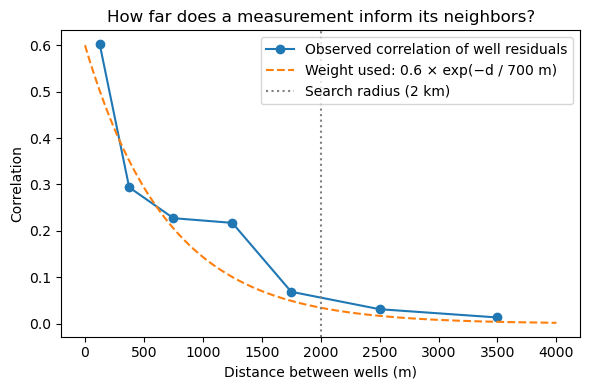

In [11]:
from scipy.spatial import cKDTree as _Tree

res_xy = np.c_[residuals.geometry.x, residuals.geometry.y]
res_values = residuals.residual.to_numpy()
pairs = _Tree(res_xy).query_pairs(4000, output_type="ndarray")
pair_distance = np.hypot(*(res_xy[pairs[:, 0]] - res_xy[pairs[:, 1]]).T)
edges = [0, 250, 500, 1000, 1500, 2000, 3000, 4000]
correlogram = []
for low, high in zip(edges[:-1], edges[1:]):
    in_bin = (pair_distance >= low) & (pair_distance < high)
    correlogram.append({"distance_m": (low + high) / 2, "pairs": int(in_bin.sum()),
                        "correlation": np.corrcoef(res_values[pairs[in_bin, 0]], res_values[pairs[in_bin, 1]])[0, 1]})
correlogram = pd.DataFrame(correlogram)
display(correlogram.round(2))

d = np.linspace(0, 4000, 200)
plt.figure(figsize=(6, 4))
plt.plot(correlogram.distance_m, correlogram.correlation, "o-", label="Observed correlation of well residuals")
plt.plot(d, 0.6 * np.exp(-d / 700), "--", label="Weight used: 0.6 × exp(−d / 700 m)")
plt.axvline(2000, color="gray", linestyle=":", label="Search radius (2 km)")
plt.xlabel("Distance between wells (m)")
plt.ylabel("Correlation")
plt.legend()
plt.title("How far does a measurement inform its neighbors?")
plt.tight_layout()
plt.show()

In [12]:
RESIDUAL_RANGE_M = 700     # residual correlation decays with distance (about 0 beyond ~2 km)
RESIDUAL_MAX_CORR = 0.6    # correlation between residuals of very close wells
SEARCH_RADIUS_M = 2000

well_xy = np.c_[residuals.geometry.x, residuals.geometry.y]
tree = cKDTree(well_xy)
cell_xy = np.c_[cells.x, cells.y]
correction = np.zeros(len(cells))
for i, neighbors in enumerate(tree.query_ball_point(cell_xy, SEARCH_RADIUS_M)):
    if neighbors:
        distance = np.hypot(*(well_xy[neighbors] - cell_xy[i]).T)
        weight = RESIDUAL_MAX_CORR * np.exp(-distance / RESIDUAL_RANGE_M)
        correction[i] = (weight * residuals.residual.to_numpy()[neighbors]).sum() / (1 + weight.sum())

cells["hybrid_correction"] = correction
cells["hybrid_probability"] = (cells["model_probability"] + correction).clip(0, 1)
cells["hybrid_risk_level"] = pd.cut(cells.hybrid_probability, RISK_BINS, right=False, labels=RISK_LABELS)

print(f"Mean absolute correction: {np.abs(correction).mean():.3f}")
display(pd.crosstab(cells.model_risk_level, cells.hybrid_risk_level, margins=True,
                    rownames=["Model"], colnames=["Hybrid"]))

Mean absolute correction: 0.058


Hybrid,Low (<25%),Moderate (25-50%),High (>50%),All
Model,,,,
Low (<25%),4275,150,4,4429
Moderate (25-50%),325,757,197,1279
High (>50%),5,221,1331,1557
All,4605,1128,1532,7265


## 6. Maps

One map per version, with the same colors and legend.

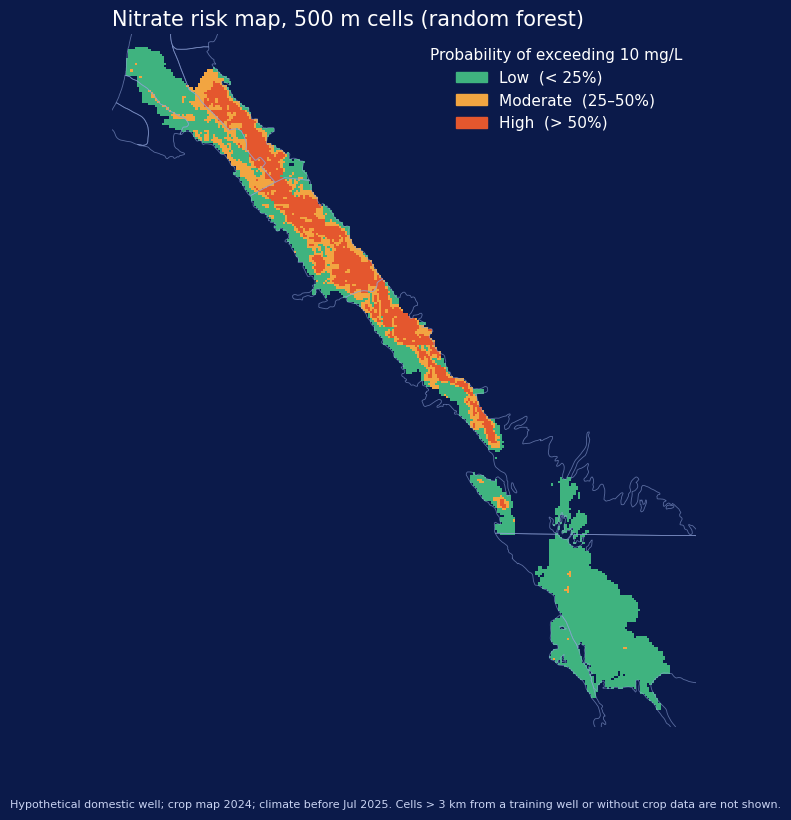

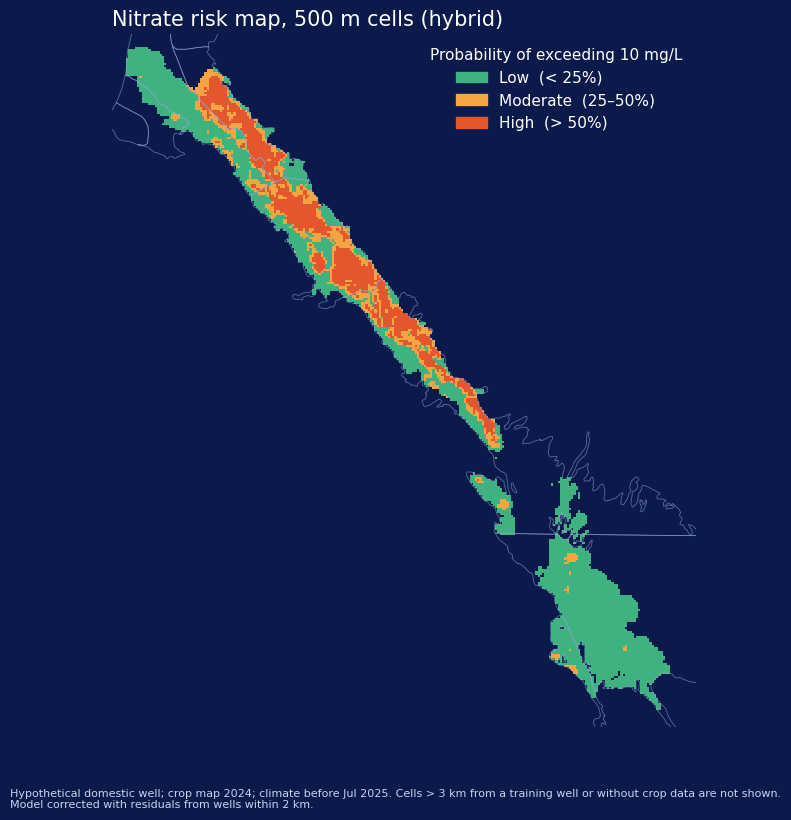

In [13]:
BG, FG = "#0b1a4a", "white"
cmap = mcolors.ListedColormap(["#3fb37f", "#f2a541", "#e4572e"])
norm = mcolors.BoundaryNorm([0, 0.25, 0.5, 1], 3)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RUN = f"{CELL_SIZE_M}m" + ("_test" if TEST_CELLS else "")

col = np.round((cells.x - cells.x.min()) / CELL_SIZE_M).astype(int)
row = np.round((cells.y - cells.y.min()) / CELL_SIZE_M).astype(int)
extent = [cells.x.min() - CELL_SIZE_M / 2, cells.x.max() + CELL_SIZE_M / 2,
          cells.y.min() - CELL_SIZE_M / 2, cells.y.max() + CELL_SIZE_M / 2]


def plot_risk_map(column, title, note, filename):
    image = np.full((row.max() + 1, col.max() + 1), np.nan)
    image[row, col] = cells[column]
    fig, ax = plt.subplots(figsize=(8, 9), facecolor=BG)
    ax.set_facecolor(BG)
    subbasins.boundary.plot(ax=ax, color="#8fa3d9", linewidth=0.6, alpha=0.6)
    ax.imshow(image, origin="lower", extent=extent, cmap=cmap, norm=norm, interpolation="nearest")
    ax.set_xlim(extent[0] - 3000, extent[1] + 3000)
    ax.set_ylim(extent[2] - 3000, extent[3] + 3000)
    ax.set_aspect("equal")
    ax.axis("off")
    legend = [Patch(color="#3fb37f", label="Low  (< 25%)"), Patch(color="#f2a541", label="Moderate  (25–50%)"),
              Patch(color="#e4572e", label="High  (> 50%)")]
    leg = ax.legend(handles=legend, loc="upper right", frameon=False, fontsize=11, labelcolor=FG,
                    title="Probability of exceeding 10 mg/L", title_fontsize=11)
    leg.get_title().set_color(FG)
    ax.set_title(title, color=FG, fontsize=15, loc="left")
    fig.text(0.02, 0.02, note, color="#c9d3f2", fontsize=8)
    plt.savefig(RESULTS_DIR / filename, dpi=200, facecolor=BG, bbox_inches="tight")
    plt.show()


base_note = (f"Hypothetical domestic well; crop map {CROP_YEAR}; climate before {REFERENCE_DATE:%b %Y}. "
             f"Cells > {MAX_DISTANCE_TO_WELL_M / 1000:g} km from a training well or without crop data are not shown.")

plot_risk_map("model_probability", f"Nitrate risk map, {CELL_SIZE_M} m cells (random forest)",
              base_note, f"risk_map_{RUN}_model.png")
plot_risk_map("hybrid_probability", f"Nitrate risk map, {CELL_SIZE_M} m cells (hybrid)",
              base_note + f"\nModel corrected with residuals from wells within {SEARCH_RADIUS_M / 1000:g} km.",
              f"risk_map_{RUN}_hybrid.png")

## 6b. Comparing the two maps

How much the measurements change the map, where they change it, and where monitoring could help most.

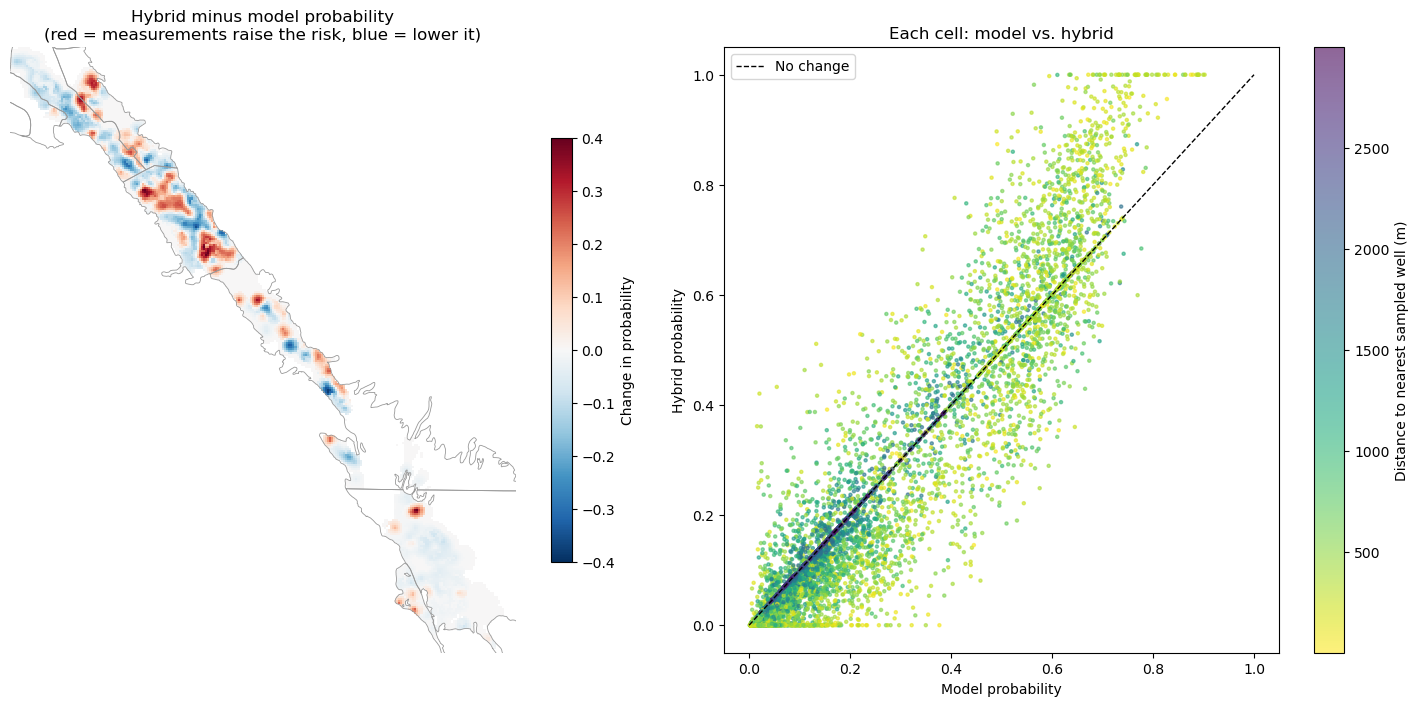

,cells,mean_change,mean_absolute_change
distance_band,,,
< 0.5 km,2620,-0.001,0.086
0.5-1 km,2158,-0.007,0.067
1-2 km,1789,-0.003,0.032
2-3 km,698,0.000,0.000


In [14]:
# Distance from each cell center to the nearest sampled well (any well)
all_wells = data.drop_duplicates("gm_well_id")
all_wells = gpd.GeoDataFrame(all_wells, geometry=gpd.points_from_xy(all_wells.gm_longitude, all_wells.gm_latitude),
                             crs=4326).to_crs(METRIC_CRS)
nearest_well_m, _ = cKDTree(np.c_[all_wells.geometry.x, all_wells.geometry.y]).query(np.c_[cells.x, cells.y])
cells["nearest_well_m"] = nearest_well_m
cells["hybrid_minus_model"] = cells["hybrid_probability"] - cells["model_probability"]

image = np.full((row.max() + 1, col.max() + 1), np.nan)
image[row, col] = cells["hybrid_minus_model"]
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
subbasins.boundary.plot(ax=axs[0], color="#999999", linewidth=0.6)
im = axs[0].imshow(image, origin="lower", extent=extent, cmap="RdBu_r", vmin=-0.4, vmax=0.4, interpolation="nearest")
axs[0].set_aspect("equal")
axs[0].axis("off")
axs[0].set_title("Hybrid minus model probability\n(red = measurements raise the risk, blue = lower it)")
fig.colorbar(im, ax=axs[0], shrink=0.7, label="Change in probability")

has_pred = cells["model_probability"].notna()
sc = axs[1].scatter(cells.loc[has_pred, "model_probability"], cells.loc[has_pred, "hybrid_probability"],
                    c=np.minimum(cells.loc[has_pred, "nearest_well_m"], 3000), cmap="viridis_r", s=5, alpha=0.6)
axs[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="No change")
axs[1].set(xlabel="Model probability", ylabel="Hybrid probability", title="Each cell: model vs. hybrid")
axs[1].legend(loc="upper left")
fig.colorbar(sc, ax=axs[1], label="Distance to nearest sampled well (m)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / f"risk_map_{RUN}_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

by_distance = (cells[has_pred]
               .assign(distance_band=pd.cut(cells.loc[has_pred, "nearest_well_m"], [0, 500, 1000, 2000, 3000, np.inf],
                                            labels=["< 0.5 km", "0.5-1 km", "1-2 km", "2-3 km", "> 3 km"]))
               .groupby("distance_band", observed=True)["hybrid_minus_model"]
               .agg(cells="size", mean_change="mean", mean_absolute_change=lambda s: s.abs().mean()))
display(by_distance.round(3))

### Two-color map at the team's threshold

Cells where the hybrid probability is at least `DECISION_THRESHOLD` (0.4, chosen in `final_results.ipynb`) are predicted to exceed 10 mg/L.

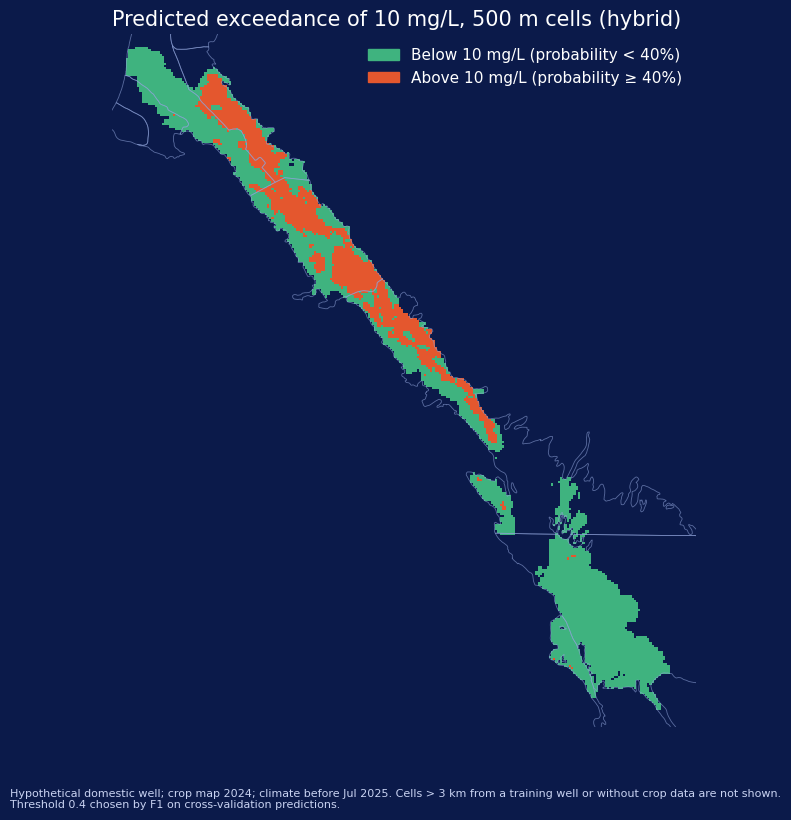

In [15]:
binary_cmap = mcolors.ListedColormap(["#3fb37f", "#e4572e"])
binary_norm = mcolors.BoundaryNorm([0, DECISION_THRESHOLD, 1.0001], 2)
image = np.full((row.max() + 1, col.max() + 1), np.nan)
image[row, col] = cells["hybrid_probability"]

fig, ax = plt.subplots(figsize=(8, 9), facecolor=BG)
ax.set_facecolor(BG)
subbasins.boundary.plot(ax=ax, color="#8fa3d9", linewidth=0.6, alpha=0.6)
ax.imshow(image, origin="lower", extent=extent, cmap=binary_cmap, norm=binary_norm, interpolation="nearest")
ax.set_xlim(extent[0] - 3000, extent[1] + 3000)
ax.set_ylim(extent[2] - 3000, extent[3] + 3000)
ax.set_aspect("equal")
ax.axis("off")
legend = [Patch(color="#3fb37f", label=f"Below 10 mg/L (probability < {DECISION_THRESHOLD:.0%})"),
          Patch(color="#e4572e", label=f"Above 10 mg/L (probability ≥ {DECISION_THRESHOLD:.0%})")]
leg = ax.legend(handles=legend, loc="upper right", frameon=False, fontsize=11, labelcolor=FG)
ax.set_title(f"Predicted exceedance of 10 mg/L, {CELL_SIZE_M} m cells (hybrid)", color=FG, fontsize=15, loc="left")
fig.text(0.02, 0.02, base_note + f"\nThreshold {DECISION_THRESHOLD} chosen by F1 on cross-validation predictions.",
         color="#c9d3f2", fontsize=8)
plt.savefig(RESULTS_DIR / f"risk_map_{RUN}_hybrid_binary.png", dpi=200, facecolor=BG, bbox_inches="tight")
plt.show()

### Where monitoring could help most

Cells predicted to exceed 10 mg/L (hybrid probability ≥ `DECISION_THRESHOLD`) with **no sampled well within 1 km**. Here the estimate rests on the model alone, so new samples would add the most information.

318 priority cells (4% of predicted cells)


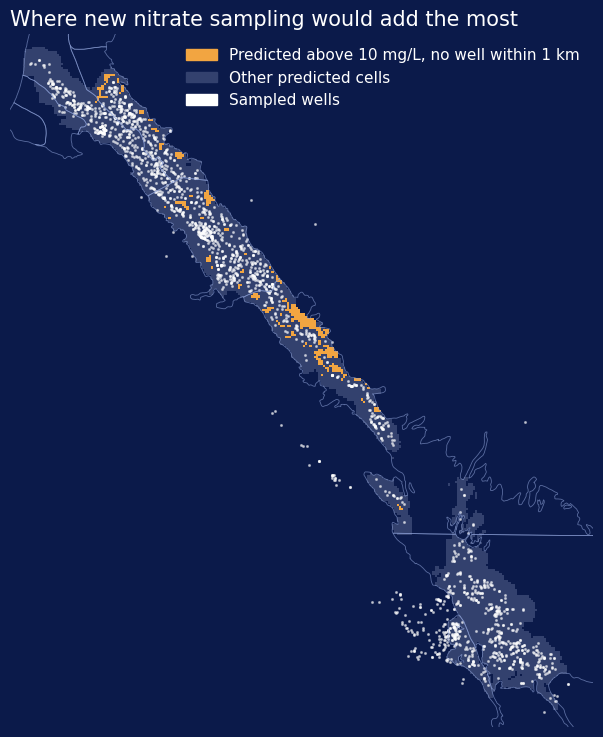

In [16]:
cells["monitoring_priority"] = (cells["hybrid_probability"] >= DECISION_THRESHOLD) & (cells["nearest_well_m"] > 1000)
print(f"{int(cells.monitoring_priority.sum()):,} priority cells "
      f"({cells.monitoring_priority.sum() / has_pred.sum():.0%} of predicted cells)")

fig, ax = plt.subplots(figsize=(8, 9), facecolor=BG)
ax.set_facecolor(BG)
subbasins.boundary.plot(ax=ax, color="#8fa3d9", linewidth=0.6, alpha=0.6)
base = np.full((row.max() + 1, col.max() + 1), np.nan)
base[row, col] = np.where(has_pred, 0.5, np.nan)
ax.imshow(base, origin="lower", extent=extent, cmap=mcolors.ListedColormap(["#33416e"]), interpolation="nearest")
priority = np.full((row.max() + 1, col.max() + 1), np.nan)
priority[row, col] = np.where(cells["monitoring_priority"], 1.0, np.nan)
ax.imshow(priority, origin="lower", extent=extent, cmap=mcolors.ListedColormap(["#f2a541"]), interpolation="nearest")
ax.scatter(all_wells.geometry.x, all_wells.geometry.y, s=1.5, color="white", alpha=0.5)
ax.set_xlim(extent[0] - 3000, extent[1] + 3000)
ax.set_ylim(extent[2] - 3000, extent[3] + 3000)
ax.set_aspect("equal")
ax.axis("off")
legend = [Patch(color="#f2a541", label="Predicted above 10 mg/L, no well within 1 km"),
          Patch(color="#33416e", label="Other predicted cells"),
          Patch(color="white", label="Sampled wells")]
leg = ax.legend(handles=legend, loc="upper right", frameon=False, fontsize=11, labelcolor=FG)
ax.set_title("Where new nitrate sampling would add the most", color=FG, fontsize=15, loc="left")
plt.savefig(RESULTS_DIR / f"risk_map_{RUN}_monitoring_priority.png", dpi=200, facecolor=BG, bbox_inches="tight")
plt.show()

## 7. Save

One table with both versions (CSV in `results/`, GeoPackage in `data/outputs/`), and one GeoTIFF per version for raster tools in ArcGIS (Weighted Overlay, Raster Calculator).

In [17]:
out = cells[["gm_well_id", "x", "y", "gm_latitude", "gm_longitude", "has_crop_data",
             "model_probability", "model_risk_level", "hybrid_correction",
             "hybrid_probability", "hybrid_risk_level",
             "nearest_well_m", "monitoring_priority"]].rename(columns={"gm_well_id": "cell_id"})
out.to_csv(RESULTS_DIR / f"risk_map_{RUN}.csv", index=False)

LOCAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
polygons = gpd.GeoDataFrame(out, geometry=[box(x - CELL_SIZE_M / 2, y - CELL_SIZE_M / 2,
                                               x + CELL_SIZE_M / 2, y + CELL_SIZE_M / 2)
                                           for x, y in zip(out.x, out.y)], crs=METRIC_CRS)
for level in ["model_risk_level", "hybrid_risk_level"]:
    polygons[level] = polygons[level].astype("string")
polygons.to_file(LOCAL_OUTPUT_DIR / f"risk_map_{RUN}.gpkg", driver="GPKG")

# One GeoTIFF per version (NoData where there is no prediction)
from rasterio.transform import from_origin
tif_col = np.round((cells.x - cells.x.min()) / CELL_SIZE_M).astype(int)
tif_row = np.round((cells.y.max() - cells.y) / CELL_SIZE_M).astype(int)      # row 0 = north
transform = from_origin(cells.x.min() - CELL_SIZE_M / 2, cells.y.max() + CELL_SIZE_M / 2,
                        CELL_SIZE_M, CELL_SIZE_M)
for version in ["model", "hybrid"]:
    grid = np.full((tif_row.max() + 1, tif_col.max() + 1), np.nan, dtype="float32")
    grid[tif_row, tif_col] = cells[f"{version}_probability"]
    with rasterio.open(LOCAL_OUTPUT_DIR / f"risk_map_{RUN}_{version}_probability.tif", "w", driver="GTiff",
                       height=grid.shape[0], width=grid.shape[1], count=1, dtype="float32",
                       crs=f"EPSG:{METRIC_CRS}", transform=transform, nodata=np.nan) as dst:
        dst.write(grid, 1)

print("Saved:", RESULTS_DIR / f"risk_map_{RUN}.csv")
print("Saved:", LOCAL_OUTPUT_DIR / f"risk_map_{RUN}.gpkg", "and two GeoTIFFs")

Saved: C:\Users\lomel\Documents\Data Science\GitHub\fall-2026-infrastructure-placement\results\risk_map\risk_map_500m.csv
Saved: C:\Users\lomel\Documents\Data Science\GitHub\fall-2026-infrastructure-placement\data\outputs\risk_map_500m.gpkg and two GeoTIFFs


## 8. Notes and limitations

- **Probabilities:** the random forest is tuned for the Brier score (no class weights), so its probabilities can be read as probabilities. Low/Moderate/High is a display choice; the team's decision threshold for calling an exceedance can be shown as a two-color map.
- **Each cell is a hypothetical domestic well** sampled on `REFERENCE_DATE`, with the `CROP_YEAR` crop map. Well depth is unknown, as in the training data.
- **Model domain:** cells farther than `MAX_DISTANCE_TO_WELL_M` from any training well, or with no DWR crop polygons within 1 km, are not predicted.
- **Location effects:** subbasin indicators carry much of the predictive power, so the map mostly reflects differences between aquifers, refined by local land use and soils.
- **The hybrid only changes cells near sampled wells** (within 2 km); elsewhere it equals the model. Its residual weights (700 m range, 0.6 maximum correlation) were set by eye from the residual correlogram, not optimized. With `FIT_ON = "all"`, the residuals come from the cross-validation predictions of folds 0–3 (hold-out wells contribute no residuals), while the map model also learned from the hold-out wells.
- **Not validated as a map:** performance was measured at wells (10 km spatial folds). The fold 4 holdout is reserved for the final evaluation of the chosen model.
- **Monitoring priority** marks predicted exceedances with no sampled well within 1 km; it ignores where domestic wells actually are, which would be the next layer to add.